# Complex analysis 2: Analytic functions and the Cauchy–Riemann equations

*Learning path: complex analysis, part 2 of 8.* [Index](README.md) · Previous: [Complex functions](01-complex-functions.ipynb) · Next: [Contour integrals](03-contour-integrals.ipynb)

On the real line, a function can have a first derivative and no second one, like $x|x|$. In the complex plane that
cannot happen: a function with one complex derivative has derivatives of every order, equals its Taylor series, and its
real and imaginary parts solve Laplace's equation, the equation of steady heat flow, electrostatics and ideal fluid
flow. The reason is a pair of equations found by Cauchy and Riemann, which this lesson derives and puts to work.

**Who this is for.** You have done [lesson 1](01-complex-functions.ipynb) and know partial derivatives
([multivariable calculus 2](../multivariable/02-partial-derivatives-and-gradient.ipynb)).

**What you will be able to do afterwards:**

1. compute a complex derivative as a limit, and see why it must be the same from every direction;
2. derive and test the Cauchy–Riemann equations $u_x = v_y$, $u_y = -v_x$;
3. show that the real and imaginary parts of an analytic function are harmonic, and that their level curves cross at
   right angles;
4. find a harmonic conjugate, and from it the analytic function.

Plan about an hour.

## 1. The complex derivative

The derivative is defined as on the real line,

$$f'(z) = \lim_{h \to 0}\frac{f(z + h) - f(z)}{h},$$

but now $h$ is complex and can approach 0 from any direction. The limit has to be the same for all of them. For
$f(z) = z^2$ at $z = 2$, approach along the real axis ($h = t$) and along the imaginary axis ($h = it$):

In [1]:
limit(((2 + t)^2 - 4)/t, t, 0)
limit(((2 + i*t)^2 - 4)/(i*t), t, 0)

4

> `limit`: Limit of f as x approaches a, from both sides or one side.

4

> `limit`: Limit of f as x approaches a, from both sides or one side.

Both give 4, as they must: $(z^2)' = 2z$. Now try the conjugate $f(z) = \bar z$:

In [2]:
limit((conj(2 + t) - conj(2))/t, t, 0)
limit((conj(2 + i*t) - conj(2))/(i*t), t, 0)

1

> `limit`: Limit of f as x approaches a, from both sides or one side.

-1

> `limit`: Limit of f as x approaches a, from both sides or one side.

The two directions disagree, $1$ against $-1$, so $\bar z$ has **no** complex derivative anywhere, even though it is as
smooth as can be as a map of the plane. A function with a complex derivative at every point of an open set is called
**analytic** (or holomorphic) there. Polynomials, $e^z$, $\sin z$ and quotients away from zeros of the denominator are
analytic, and the usual rules apply:

In [3]:
diff(z^3 + 1/z, z)
diff(exp(z^2), z)

3*z^2-1/z^2

> `diff` (see `deriv`): Derivative of expr with respect to the variable given (other letters count as constants: a partial derivative).

2*exp(z^2)*z

> `diff` (see `deriv`): Derivative of expr with respect to the variable given (other letters count as constants: a partial derivative).

**Try this.** Test $f(z) = |z|^2 = z\bar z$ at $z = 1$ in the two directions. Then at $z = 0$. Where is it
differentiable?

## 2. The Cauchy–Riemann equations

Write $f = u + iv$. Along the real direction the difference quotient tends to $u_x + i v_x$; along the imaginary
direction, dividing by $it$, it tends to $(u_y + i v_y)/i = v_y - i u_y$. Setting the two equal gives the
**Cauchy–Riemann equations**

$$u_x = v_y, \qquad u_y = -v_x.$$

For $f(z) = z^3$:

In [4]:
u = real((x + i*y)^3)
v = imag((x + i*y)^3)
simplify([diff(u, x) - diff(v, y), diff(u, y) + diff(v, x)])

x^3-3*x*y^2

> `real`: Real part, imaginary part, complex conjugate, modulus |z| and argument (angle) of z.

3*x^2*y-y^3

> `imag` (see `real`): Real part, imaginary part, complex conjugate, modulus |z| and argument (angle) of z.

[0, 0]

> `simplify`: Combines fractions, cancels common factors and applies sin^2 + cos^2 = 1, keeping the simplest form.

Both equations hold everywhere. For $\bar z$, with $u = x$ and $v = -y$, the first fails: $u_x - v_y = 2$.

In [5]:
simplify([diff(x, x) - diff(-y, y), diff(x, y) + diff(-y, x)])

[2, 0]

> `simplify`: Combines fractions, cancels common factors and applies sin^2 + cos^2 = 1, keeping the simplest form.

Conversely, if $u$ and $v$ have continuous partial derivatives that satisfy the equations, $f$ is analytic, and
$f' = u_x + i v_x$. For the exponential, $u = e^x\cos y$ and $v = e^x\sin y$:

In [6]:
ue = exp(x)*cos(y);
ve = exp(x)*sin(y);
simplify([diff(ue, x) - diff(ve, y), diff(ue, y) + diff(ve, x)])

[0, 0]

> `simplify`: Combines fractions, cancels common factors and applies sin^2 + cos^2 = 1, keeping the simplest form.

and $f' = u_x + iv_x = e^x\cos y + i e^x\sin y = e^z$: the exponential is its own derivative in the complex plane too.

**Try this.** Check the Cauchy–Riemann equations for $f(z) = 1/z$, using `real(1/(x + i*y))` and
`imag(1/(x + i*y))`. Where do they fail?

## 3. Harmonic functions

Differentiate the first equation by $x$ and the second by $y$ and add: $u_{xx} + u_{yy} = v_{yx} - v_{xy} = 0$. So the
real part of an analytic function satisfies **Laplace's equation** $\nabla^2 u = 0$; it is **harmonic**, and so is the
imaginary part.

In [7]:
laplacian(u, [x y])
laplacian(v, [x y])
laplacian(x^2 + y^2, [x y])

0

> The Laplacian is div(grad f): the sum of the second partial derivatives in Cartesian coordinates. It compares f at a point with its average nearby; functions with Laplacian 0 are harmonic (steady temperatures, electrostatic potentials in empty space).

0

> The Laplacian is div(grad f): the sum of the second partial derivatives in Cartesian coordinates. It compares f at a point with its average nearby; functions with Laplacian 0 are harmonic (steady temperatures, electrostatic potentials in empty space).

4

> The Laplacian is div(grad f): the sum of the second partial derivatives in Cartesian coordinates. It compares f at a point with its average nearby; functions with Laplacian 0 are harmonic (steady temperatures, electrostatic potentials in empty space).

$x^2 + y^2$ is not harmonic, so it is not the real part of any analytic function. Harmonic functions describe steady
temperatures, electrostatic potentials and the velocity potential of an ideal fluid, which is why complex analysis is a
working tool in physics and engineering ([lesson 8](08-conformal-maps.ipynb) uses it for flow around a wing).

The Cauchy–Riemann equations also say that $\nabla u \cdot \nabla v = u_x v_x + u_y v_y = v_y v_x - v_x v_y = 0$: the
gradients are perpendicular, so **the level curves of $u$ and $v$ cross at right angles**. For $z^2$, $u = x^2 - y^2$
and $v = 2xy$ are two families of hyperbolas:

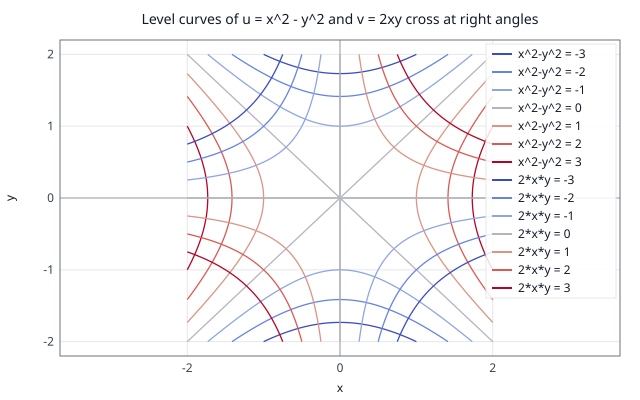

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [8]:
p = contour(x^2 - y^2, x, -2, 2, y, -2, 2, [-3 -2 -1 0 1 2 3]);
p = show(p, contour(2*x*y, x, -2, 2, y, -2, 2, [-3 -2 -1 0 1 2 3]));
labels(title(p, "Level curves of u = x^2 - y^2 and v = 2xy cross at right angles"), "x", "y")

**Try this.** Check that $u = \log(x^2 + y^2)/2$, the real part of $\log z$, is harmonic away from the origin. What
physical situation does it describe? (Hint: the potential of a line charge.)

## 4. Harmonic conjugates

Given a harmonic $u$, the Cauchy–Riemann equations determine $v$ up to a constant: $v_y = u_x$ fixes $v$ as a function
of $y$, and $v_x = -u_y$ fixes the rest. Such a $v$ is a **harmonic conjugate** of $u$. Start from
$u = x^2 - y^2 + x$:

In [9]:
u3 = x^2 - y^2 + x;
laplacian(u3, [x y])
v3 = integrate(diff(u3, x), y)
simplify(diff(v3, x) + diff(u3, y))

0

> The Laplacian is div(grad f): the sum of the second partial derivatives in Cartesian coordinates. It compares f at a point with its average nearby; functions with Laplacian 0 are harmonic (steady temperatures, electrostatic potentials in empty space).

2*x*y+y

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

0

> `simplify`: Combines fractions, cancels common factors and applies sin^2 + cos^2 = 1, keeping the simplest form.

Integrating $u_x = 2x + 1$ in $y$ gives $v = 2xy + y$, and the second equation holds with no extra function of $x$
needed. So $f = u + iv = x^2 - y^2 + x + i(2xy + y) = z^2 + z$:

In [10]:
simplify(expand((x + i*y)^2 + (x + i*y)) - (u3 + i*v3))

0

> `simplify`: Combines fractions, cancels common factors and applies sin^2 + cos^2 = 1, keeping the simplest form.

**Try this.** Find a harmonic conjugate of $u = e^x\cos y$ by the same steps. Which analytic function do you get?

## Summary

* $f'(z) = \lim_{h \to 0}(f(z + h) - f(z))/h$ must be the same from every direction; $\bar z$ and $|z|^2$ fail this.
* With $f = u + iv$: $f$ is analytic exactly when $u_x = v_y$ and $u_y = -v_x$ (with continuous partials), and then
  $f' = u_x + iv_x$.
* Real and imaginary parts of analytic functions are harmonic, $\nabla^2 u = \nabla^2 v = 0$, and their level curves
  cross at right angles.
* A harmonic $u$ has a harmonic conjugate $v$, found by integrating the Cauchy–Riemann equations; $u + iv$ is analytic.

Next: [contour integrals](03-contour-integrals.ipynb).

## Exercises

1. **Where analytic?** Show that $f(z) = x^2 + iy^2$ satisfies the Cauchy–Riemann equations only on the line $y = x$.
   Is it analytic anywhere?
2. **Sine.** Find $u$ and $v$ for $\sin z$, check the Cauchy–Riemann equations, and compute $f' = u_x + iv_x$.
3. **Not harmonic.** Show that $u = x^3 + y^3$ is not the real part of an analytic function.
4. **Conjugate.** Find the harmonic conjugate of $u = x^3 - 3xy^2$ and the analytic function $u + iv$.
5. **Polar form.** In polar coordinates the equations read $u_r = v_\theta/r$, $v_r = -u_\theta/r$. Check them for
   $\log z = \log r + i\theta$.

## Hints and answers

* **Section 1, Try this.** At $z = 1$: 2 along the real axis and 0 along the imaginary one. At $z = 0$ both give 0:
  $|z|^2$ is differentiable only at the origin, and so analytic nowhere.
* **Section 2, Try this.** $u = x/(x^2 + y^2)$, $v = -y/(x^2 + y^2)$; the equations hold everywhere except at
  $z = 0$, where $1/z$ is undefined.
* **Section 3, Try this.** `simplify(laplacian(log(x^2 + y^2)/2, [x y]))` is 0. It is the potential of a uniform line
  charge through the origin, perpendicular to the plane.
* **Section 4, Try this.** $v = e^x\sin y$, and $u + iv = e^z$.
* **Exercise 1.** $u_x = 2x$, $v_y = 2y$, $u_y = 0 = -v_x$: they agree only on $y = x$, a line, which contains no open
  set. Analytic nowhere.
* **Exercise 2.** $u = \sin x\cosh y$, $v = \cos x\sinh y$; $f' = \cos x\cosh y - i\sin x\sinh y = \cos z$.
* **Exercise 3.** $\nabla^2 u = 6x + 6y \ne 0$.
* **Exercise 4.** $v = 3x^2y - y^3$, and $u + iv = z^3$.
* **Exercise 5.** $u = \log r$, $v = \theta$: $u_r = 1/r = v_\theta/r$ and $v_r = 0 = -u_\theta/r$.

## Sources

1. A. L. Cauchy, *Mémoire sur les intégrales définies*, read 1814, published 1827.
2. B. Riemann, *Grundlagen für eine allgemeine Theorie der Functionen einer veränderlichen complexen Grösse*,
   dissertation, Göttingen (1851).
3. T. Needham, *Visual Complex Analysis*, Oxford University Press (1997), chapters 4 and 11.
4. E. M. Stein and R. Shakarchi, *Complex Analysis*, Princeton University Press (2003), chapter 1.